# What do the male pC1 neurons do to the song neurons?

MaleCNS has about 156 neurons whose cell type starts with `pC1`, and the song neurons `pIP10` and `vPR6` / `vPR9_*`. This notebook asks which `pC1_*` types synapse onto those song neurons, and which of them change the song neurons' firing when they are injected with current.

Two kinds of result, kept separate:

- **Wiring.** Direct synaptic input, and two-step paths, from `weights.npz`. Weights are the model's signed, input-normalized synapse weights: for each postsynaptic neuron the absolute incoming weights sum to 1 (`flybrain/build.py`). A direct share of 0.03 is 3% of that neuron's synaptic input. It is not a raw synapse count. A two-step score is the mean, over the target neurons, of `W[target, mid] * W[mid, source]` summed over intermediates and over the source neurons of one `pC1` type. Those products are not percentages of input. The two-step score does not include the direct edge.
- **Simulation.** Current injection into every neuron of one `pC1` type, on the real MaleCNS network (`FlyBrain`, default tonic 0.14, gain 3.0, 20 ms steps). Photoreceptors are not driven.

Seeds, the survey strength, and the decision rule are fixed in the next cell before any run. A strength curve then repeats the strongest type, the near-zero type and the seed-0 random group on a grid that is extended downward until a pIP10 or pMP2 readout stops rising, or until 0.001 V/step. A matched-noise blank (same seed, no injection) is subtracted. Controls, also fixed before the runs: every other `pC1` type (each type is stimulated), five random `cb_intrinsic` groups of the same size as the `pC1` type with the largest absolute direct share onto `pIP10` (`numpy` generators, seeds 0 through 4), and a shuffled-weights brain. The shuffle permutes synapse weights inside each postsynaptic neuron, so each cell keeps its incoming weights (`numpy` generator seed 1), and that brain is given its own blank. It is rerun for the strongest type, the type with the smallest absolute direct share, and the seed-0 random group, then the weights are restored.

`pIP10` and `pMP2` are included because both are descending song neurons in Shiozaki et al. 2024. `pMP2` is not a `vPR` neuron. The superclass of every `vPR*` type is printed from the file. Literature is a hypothesis, not a result (citations at the end). The annotation synonyms are printed from the MaleCNS table. No `pC1_*` string is treated as P1 unless that table says so.


In [1]:
from pathlib import Path
import platform
import sys
import time

import matplotlib.pyplot as plt
import numba
import numpy as np
from scipy import sparse

import flybrain
from flybrain import DATA, FlyBrain

# Fixed before the runs.
SEEDS = tuple(range(8))
STEPS = 100            # 2.0 s at the default 20 ms step
ON, OFF = 25, 75       # injection during the middle 1.0 s
STRENGTH = 0.8         # volts added each step for the type survey, same scale as inject.py
# Strength curve. The survey is one point. This grid is what gets extended downward
# until a descending readout of the strongest type does not move, or 0.001 V/step.
CURVE_GRID = (0.02, 0.05, 0.1, 0.2, 0.4, 0.8, 1.2, 2.0)
DIRECT_PREDICT = 0.01  # |signed share| at or above this is a direct prediction
MOVE_HZ = 1.0
MOVE_T = 3.0           # same bar as inject.py: |mean| / se
CONTROL_SEED = 0
N_RANDOM = 5          # independent draws, seeds CONTROL_SEED .. CONTROL_SEED + N_RANDOM - 1
SHUFFLE_SEED = 1
TOP_TWO = 5
TOP_DIRECT_PLOT = 12

def figures_dir():
    here = Path.cwd().resolve()
    for d in [here, *here.parents]:
        if (d / "courtship.ipynb").is_file():
            return d / "courtship-figures"
        if (d / "notebooks" / "courtship.ipynb").is_file():
            return d / "notebooks" / "courtship-figures"
    raise FileNotFoundError(
        "courtship.ipynb was not found in the working directory or a parent. "
        "Run this notebook from the repository, or from notebooks/."
    )

FIG = figures_dir()
FIG.mkdir(parents=True, exist_ok=True)
print("figures", FIG)

print("python", sys.version.split()[0], "platform", platform.platform(), "machine", platform.machine())
print("numpy", np.__version__, "numba", numba.__version__, "threads", numba.get_num_threads())
print("flybrain", flybrain.__version__ if hasattr(flybrain, "__version__") else "?", flybrain.__file__)
print("seeds", SEEDS, "steps", STEPS, "stim_window_s", (OFF - ON) * 0.02, "survey_strength", STRENGTH)
print("curve_grid_V_per_step", CURVE_GRID)
print("control_seed", CONTROL_SEED, "shuffle_seed", SHUFFLE_SEED)

t0 = time.perf_counter()
brain = FlyBrain(device="cpu", seed=0)
print(f"loaded {brain.n:,} neurons in {time.perf_counter() - t0:.1f}s  dt={brain.dt} tonic={brain.tonic:.4f} gain={brain.gain}")

ct = np.array([str(x) for x in brain.cell_type])
sc = np.array([str(x) for x in brain.superclass])
side = np.array([str(x) for x in brain.side])

def neurons(name, which=None):
    idx = np.flatnonzero(ct == name)
    if which is None:
        return idx
    return idx[side[idx] == which]

pc1_idx = np.flatnonzero(np.char.startswith(ct, "pC1"))
pc1_types = sorted(set(ct[pc1_idx].tolist()))
print(f"pC1 neurons {len(pc1_idx)}  types {len(pc1_types)}  superclasses {sorted(set(sc[pc1_idx].tolist()))}")
print("cell type exactly 'P1':", int((ct == "P1").sum()), "  startswith 'P1':", int(np.char.startswith(ct, "P1").sum()))

# Synonyms live in the MaleCNS annotation table, not in brain.npz. Same file build.py downloads.
import re
import urllib.request
from collections import Counter
import pyarrow.feather as feather

ANN_NAME = "body-annotations-male-cns-v1.0-minconf-0.5.feather"
ann_path = DATA / "raw" / ANN_NAME
if not ann_path.exists():
    ann_path.parent.mkdir(parents=True, exist_ok=True)
    url = "https://storage.googleapis.com/flyem-male-cns/v1.0/connectome-data/flat-connectome/" + ANN_NAME
    print("downloading", ANN_NAME)
    urllib.request.urlretrieve(url, ann_path)
ann = feather.read_table(ann_path, columns=["flywireType", "type", "synonyms", "hemibrainType"])
fw = ann.column("flywireType").to_pylist()
typ_col = ann.column("type").to_pylist()
syn_col = ann.column("synonyms").to_pylist()
hb_col = ann.column("hemibrainType").to_pylist()
stored = [a if a else (b or "") for a, b in zip(fw, typ_col)]
p1_token = re.compile(r"(^|[^A-Za-z0-9])P1([^A-Za-z0-9]|$)")
syn_counts = Counter(sy for s, sy in zip(stored, syn_col) if s.startswith("pC1"))
p1_on_pc1 = sum(
    1 for s, sy in zip(stored, syn_col)
    if s.startswith("pC1") and sy and p1_token.search(sy)
)
print("annotation synonyms on stored pC1 types (flywireType, else type), from", ann_path.name)
for sy, n_syn in syn_counts.most_common():
    print(f"  n={n_syn:3d}  {sy}")
print("pC1 neurons whose synonym contains the token P1:", p1_on_pc1)
other_p1 = Counter(
    (s, h) for s, h, sy in zip(stored, hb_col, syn_col)
    if p1_token.search(f"{s} {h or ''} {sy or ''}") and not s.startswith("pC1")
)
print("other rows whose type, hemibrainType, or synonym contains the token P1:")
if not other_p1:
    print("  none")
for (s, h), n_hit in other_p1.most_common():
    print(f"  n={n_hit} stored={s} hemibrainType={h}")

vpr_types = sorted(set(ct[np.char.startswith(ct, "vPR")].tolist()))
print("vPR types:", vpr_types)

readouts = {}
for name in ("pIP10", "pMP2", *vpr_types):
    idx = neurons(name)
    classes = sorted(set(sc[idx].tolist())) if len(idx) else []
    sides = {s: int((side[idx] == s).sum()) for s in ("L", "R", "M")}
    print(f"{name:12s} n={len(idx):3d} class={classes} sides={sides}")
    present = [s for s in ("L", "R", "M") if sides.get(s, 0)]
    if len(present) <= 1:
        readouts[f"{name}-{present[0]}" if present else name] = idx
    else:
        for s in present:
            readouts[f"{name}-{s}"] = neurons(name, s)

pip = neurons("pIP10")
assert len(pip) == 2
assert set(sc[pip].tolist()) == {"descending_neuron"}
assert set(sc[neurons("pMP2")].tolist()) == {"descending_neuron"}
for name in vpr_types:
    assert set(sc[neurons(name)].tolist()) == {"vnc_intrinsic"}, name

W = sparse.load_npz(DATA / "weights.npz").tocsr()
W.sum_duplicates()
W.sort_indices()
sample = int(pip[0])
incoming = float(np.abs(W.getrow(sample).data).sum())
print("one pIP10 neuron |incoming| sum (should be 1):", round(incoming, 5))
assert abs(incoming - 1.0) < 1e-4
print("readouts:", {k: int(len(v)) for k, v in readouts.items()})


figures /Users/thescoho/.treehouse/fly.ai-e22435/2/fly.ai/notebooks/courtship-figures
python 3.12.4 platform macOS-26.5.2-arm64-arm-64bit machine arm64
numpy 2.5.5 numba 0.68.1 threads 12
flybrain 0.1.1 /Users/thescoho/.treehouse/fly.ai-e22435/2/fly.ai/flybrain/__init__.py
seeds (0, 1, 2, 3, 4, 5, 6, 7) steps 100 stim_window_s 1.0 survey_strength 0.8
curve_grid_V_per_step (0.02, 0.05, 0.1, 0.2, 0.4, 0.8, 1.2, 2.0)
control_seed 0 shuffle_seed 1


loaded 166,700 neurons in 0.6s  dt=0.02 tonic=0.1400 gain=3.0
pC1 neurons 156  types 47  superclasses ['cb_intrinsic']
cell type exactly 'P1': 0   startswith 'P1': 0


annotation synonyms on stored pC1 types (flywireType, else type), from body-annotations-male-cns-v1.0-minconf-0.5.feather
  n= 80  Lee 2002, Rideout 2010, Nojima 2021: pC1; Cachero 2010: pMP-e; Yu 2010: pMP4
  n= 56  Lee 2002, Rideout 2010, Nojima 2021: pC1
  n=  8  Lee 2002, Rideout 2010, Nojima 2021: pC1, Sten 2025: pC1x
  n=  6  None
  n=  6  Cachero 2010: pMP-e; Yu 2010: pMP4
pC1 neurons whose synonym contains the token P1: 0
other rows whose type, hemibrainType, or synonym contains the token P1:
  n=2 stored=OA-AL2i1 hemibrainType=P1-9
vPR types: ['vPR6', 'vPR9_a', 'vPR9_b', 'vPR9_c']
pIP10        n=  2 class=['descending_neuron'] sides={'L': 1, 'R': 1, 'M': 0}
pMP2         n=  2 class=['descending_neuron'] sides={'L': 1, 'R': 1, 'M': 0}
vPR6         n=  8 class=['vnc_intrinsic'] sides={'L': 4, 'R': 4, 'M': 0}
vPR9_a       n=  4 class=['vnc_intrinsic'] sides={'L': 0, 'R': 0, 'M': 4}
vPR9_b       n=  2 class=['vnc_intrinsic'] sides={'L': 0, 'R': 0, 'M': 2}
vPR9_c       n=  3 class=

In [2]:

# Column block of every pC1 neuron, outgoing weights (CSC columns of the same matrix).
W_csc = W.tocsc()
src_block = W_csc[:, pc1_idx]
pc1_pos = {int(n): i for i, n in enumerate(pc1_idx)}
type_cols = {typ: [pc1_pos[int(n)] for n in neurons(typ)] for typ in pc1_types}

direct_m = {}
two_m = {}
t0 = time.perf_counter()
for key, idx in readouts.items():
    rows = W[idx]
    direct_m[key] = rows[:, pc1_idx]
    two_m[key] = rows @ src_block
print(f"wiring products in {time.perf_counter() - t0:.1f}s")

def score(mat, typ):
    """Mean over target neurons of the summed weight (or path product) from this type."""
    cols = type_cols[typ]
    block = mat[:, cols]
    total = block.sum()
    total = float(total if np.isscalar(total) else np.asarray(total).sum())
    return total / mat.shape[0]

direct_share = {}
two_score = {}
for key in readouts:
    for typ in pc1_types:
        direct_share[(typ, key)] = score(direct_m[key], typ)
        two_score[(typ, key)] = score(two_m[key], typ)

def top_types(table, key, k):
    rows = sorted(pc1_types, key=lambda typ: abs(table[(typ, key)]), reverse=True)
    return rows[:k]

pip_keys = [k for k in readouts if k.startswith("pIP10-")]
# Pooled share onto every pIP10 neuron, for ranking only.
pip_share = {}
pip_mat = W[pip][:, pc1_idx]
pip_two = W[pip] @ src_block
for typ in pc1_types:
    cols = type_cols[typ]
    d = pip_mat[:, cols].sum()
    t = pip_two[:, cols].sum()
    pip_share[typ] = float(np.asarray(d).sum()) / len(pip)
    two_score[(typ, "pIP10-both")] = float(np.asarray(t).sum()) / len(pip)
    direct_share[(typ, "pIP10-both")] = pip_share[typ]

ranked = sorted(pc1_types, key=lambda typ: abs(pip_share[typ]), reverse=True)
strong = ranked[0]
weak = ranked[-1]
print(f"strongest |direct share| onto pIP10: {strong}  share {pip_share[strong]:+.4f}  n={len(neurons(strong))}")
print(f"smallest  |direct share| onto pIP10: {weak}  share {pip_share[weak]:+.4f}  n={len(neurons(weak))}")

print("\nDirect share onto each readout, top 8 by |share|. This is wiring, not a simulation.")
print(f"{'readout':14s} {'type':16s} {'signed':8s} {'n':4s} {'class'}")
for key in readouts:
    for typ in top_types(direct_share, key, 8):
        print(f"{key:14s} {typ:16s} {direct_share[(typ, key)]:+8.4f} {len(neurons(typ)):4d} {sc[neurons(typ)[0]]}")

print("\nTwo-step path product onto each readout, top 5 by |product|. Not a percentage.")
two_pred = {}
for key in readouts:
    preds = []
    ordered = sorted(pc1_types, key=lambda typ: abs(two_score[(typ, key)]), reverse=True)
    for typ in ordered[:TOP_TWO]:
        if abs(direct_share[(typ, key)]) >= DIRECT_PREDICT:
            continue
        preds.append(typ)
    two_pred[key] = preds
    for typ in ordered[:TOP_TWO]:
        print(f"{key:14s} {typ:16s} {two_score[(typ, key)]:+8.5f}  direct {direct_share[(typ, key)]:+8.4f}")

# Intermediates on the strongest pC1 type -> all pIP10 neurons. Wiring only.
src = neurons(strong)
incoming_from_src = np.asarray(src_block[:, type_cols[strong]].sum(axis=1)).ravel()
out_to_pip = np.asarray(W[pip].sum(axis=0)).ravel()
mid_score = incoming_from_src * out_to_pip
# The source neurons themselves are not an intermediate of interest here.
mid_score[src] = 0.0
order = np.argsort(np.abs(mid_score))[::-1]
print(f"\nTop intermediate types on {strong} -> pIP10 (sum over mids of (weight from {strong}) * (weight onto pIP10)):")
seen_mid = set()
mid_rows = []
for m in order:
    if mid_score[m] == 0:
        break
    name = ct[m]
    if name in seen_mid:
        continue
    seen_mid.add(name)
    members = neurons(name)
    total = float(mid_score[members].sum())
    mid_rows.append((abs(total), total, name, str(sc[members[0]]), len(members)))
mid_rows.sort(key=lambda row: row[0], reverse=True)
for _, total, name, klass, n_mid in mid_rows[:8]:
    print(f"  {name:22s} {total:+.5f}  class={klass}  n={n_mid}")

pool = np.flatnonzero(sc == "cb_intrinsic")
pool = pool[~np.isin(ct[pool], np.array(pc1_types))]
need = len(neurons(strong))
if len(pool) < need:
    raise RuntimeError("not enough cb_intrinsic neurons outside pC1")
random_groups = []
for g in range(N_RANDOM):
    rng = np.random.default_rng(CONTROL_SEED + g)
    pick = np.sort(rng.choice(pool, size=need, replace=False).astype(np.int64))
    random_groups.append(pick)
    print(f"Random group seed {CONTROL_SEED + g}: n={len(pick)} class=cb_intrinsic indices={pick.tolist()}")
    print("  types", sorted(set(ct[pick].tolist())))
random_idx = random_groups[0]


wiring products in 0.0s
strongest |direct share| onto pIP10: pC1_14a  share +0.0262  n=6
smallest  |direct share| onto pIP10: pC1_9b  share +0.0000  n=2

Direct share onto each readout, top 8 by |share|. This is wiring, not a simulation.
readout        type             signed   n    class
pIP10-L        pC1_14a           +0.0247    6 cb_intrinsic
pIP10-L        pC1_7b            +0.0082    4 cb_intrinsic
pIP10-L        pC1_5b            +0.0078    4 cb_intrinsic
pIP10-L        pC1_19            +0.0075    7 cb_intrinsic
pIP10-L        pC1_7a            +0.0070    4 cb_intrinsic
pIP10-L        pC1a,pC1c         +0.0044    6 cb_intrinsic
pIP10-L        pC1_11b           +0.0036    2 cb_intrinsic
pIP10-L        pC1_5a            +0.0031    2 cb_intrinsic
pIP10-R        pC1_14a           +0.0278    6 cb_intrinsic
pIP10-R        pC1_5b            +0.0121    4 cb_intrinsic
pIP10-R        pC1_7b            +0.0094    4 cb_intrinsic
pIP10-R        pC1_7a            +0.0081    4 cb_intrinsic
pI

  SIP143m                -0.00140  class=cb_intrinsic  n=4
  SIP141m                -0.00124  class=cb_intrinsic  n=6
  CB1618,CB3330          +0.00102  class=cb_intrinsic  n=12
  pMP2                   +0.00090  class=descending_neuron  n=2
  CL344                  +0.00048  class=cb_intrinsic  n=4
  ICL008m                -0.00030  class=cb_intrinsic  n=6
  SIP133m                -0.00028  class=cb_intrinsic  n=2
  pC1a,pC1c              +0.00025  class=cb_intrinsic  n=6
Random group seed 0: n=6 class=cb_intrinsic indices=[2368, 18332, 22391, 48811, 72229, 124319]
  types ['CB.FB8B0', 'CB0926', 'CB1542', 'FS4B', 'KCg-d', 'SMP520b']
Random group seed 1: n=6 class=cb_intrinsic indices=[2043, 8126, 42727, 48896, 103167, 134434]
  types ['AVLP212', 'CB1046', 'CB2132', 'KCab', 'PS268,PS269,CB3941', 'SMP700m']
Random group seed 2: n=6 class=cb_intrinsic indices=[6039, 17567, 21290, 34698, 113611, 119092]
  types ['AVLP043', 'CB1227', 'CB2966', 'CB3110', 'CB3189', 'SLP285']
Random group see

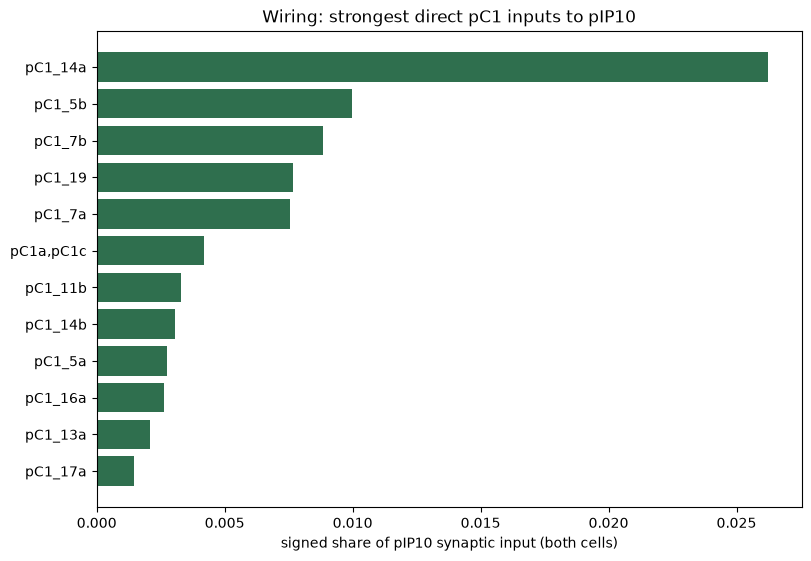

In [3]:

rows = ranked[:TOP_DIRECT_PLOT][::-1]
fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
colors = ["#c44536" if pip_share[typ] < 0 else "#2f6f4e" for typ in rows]
ax.barh(rows, [pip_share[typ] for typ in rows], color=colors)
ax.axvline(0, color="black", linewidth=0.6)
ax.set_xlabel("signed share of pIP10 synaptic input (both cells)")
ax.set_title("Wiring: strongest direct pC1 inputs to pIP10")
fig.savefig(FIG / "direct-pip10.png", dpi=140)
plt.show()


In [4]:
def trial(stim_idx, seed, strength=None):
    if strength is None:
        strength = STRENGTH
    brain.reset(int(seed))
    counts = {k: 0 for k in readouts}
    first = {k: -1 for k in readouts}
    hit = np.zeros(brain.n, np.bool_)
    for step in range(STEPS):
        if stim_idx is not None and ON <= step < OFF:
            brain.stimulate(stim_idx, strength)
        fired = brain.step()
        if ON <= step < OFF and len(fired):
            hit[:] = False
            hit[fired] = True
            for key, idx in readouts.items():
                m = hit[idx]
                counts[key] += int(m.sum())
                if first[key] < 0 and m.any():
                    first[key] = step
    dur = (OFF - ON) * brain.dt
    rates = {k: counts[k] / len(readouts[k]) / dur for k in readouts}
    latency = {k: (None if first[k] < 0 else (first[k] - ON) * brain.dt) for k in readouts}
    return rates, latency

def stack_rates(runs):
    return {k: np.array([r[k] for r in runs]) for k in readouts}

def stack_latency(runs):
    out = {}
    for k in readouts:
        vals = [r[k] for r in runs]
        fired = [v for v in vals if v is not None]
        out[k] = {
            "p_fire": len(fired) / len(vals),
            "k": len(fired),
            "n": len(vals),
            "latency_s": (None if not fired else float(np.median(fired))),
            "censored": len(vals) - len(fired),
        }
    return out

def run_condition(stim_idx, label):
    t0 = time.perf_counter()
    runs = [trial(stim_idx, seed) for seed in SEEDS]
    print(f"ran {label} ({0 if stim_idx is None else len(stim_idx)} neurons) in {time.perf_counter() - t0:.1f}s", flush=True)
    return stack_rates([r[0] for r in runs]), stack_latency([r[1] for r in runs])

t0 = time.perf_counter()
blank_rates, blank_lat = run_condition(None, "blank")

measured, latencies = {}, {}
stim_sets = {typ: neurons(typ) for typ in pc1_types}
for typ in pc1_types:
    measured[typ], latencies[typ] = run_condition(stim_sets[typ], typ)
measured["random"], latencies["random"] = run_condition(random_idx, "random seed 0")
for g in range(1, N_RANDOM):
    label = f"random-{g}"
    measured[label], latencies[label] = run_condition(random_groups[g], f"random seed {g}")
print(f"intact-wiring simulation {time.perf_counter() - t0:.1f}s")

def stats(stim_rates, base_rates=None):
    if base_rates is None:
        base_rates = blank_rates
    out = {}
    n = len(SEEDS)
    for key in readouts:
        d = stim_rates[key] - base_rates[key]
        se = d.std(ddof=1) / np.sqrt(n)
        t = float(d.mean() / se) if se > 0 else 0.0
        out[key] = {
            "delta": float(d.mean()),
            "sd": float(d.std(ddof=1)),
            "t": t,
            "blank": float(base_rates[key].mean()),
            "moves": abs(float(d.mean())) >= MOVE_HZ and abs(t) >= MOVE_T,
        }
    return out

random_labels = ["random"] + [f"random-{g}" for g in range(1, N_RANDOM)]
stim_stats = {typ: stats(measured[typ]) for typ in list(pc1_types) + random_labels}

def control_abs(key):
    return max(abs(stim_stats[label][key]["delta"]) for label in random_labels)

def permute_incoming(weights, indices, seed):
    """Permute weights inside each postsynaptic neuron. Edges stay.

    CSC `indices` are the postsynaptic targets. Each cell keeps its incoming
    weight multiset, so its absolute-input sum and its incoming signs stay.
    """
    rng = np.random.default_rng(seed)
    keys = rng.random(indices.shape[0])
    order = np.lexsort((keys, indices))
    stable = np.argsort(indices, kind="mergesort")
    out = np.array(weights, copy=True)
    out[stable] = weights[order]
    return out

# Shuffled weights: within each postsynaptic cell, seed 1. Own blank. Restore after.
original = np.array(brain.weights, copy=True)
shuffled = permute_incoming(original, brain.indices, SHUFFLE_SEED)
post = int(pip[0])
incoming_edges = brain.indices == post
print(
    "within-row shuffle: pIP10 incoming |weight| sum "
    f"before {float(np.abs(original[incoming_edges]).sum()):.5f} "
    f"after {float(np.abs(shuffled[incoming_edges]).sum()):.5f}"
)
assert np.array_equal(np.sort(original[incoming_edges]), np.sort(shuffled[incoming_edges]))
assert abs(float(np.abs(shuffled[incoming_edges]).sum()) - 1.0) < 1e-3
assert not np.array_equal(shuffled, original)
shuffled_stats = {}
shuffled_lat = {}
try:
    brain.weights[:] = shuffled
    shuf_blank_rates, shuf_blank_lat = run_condition(None, "shuffled blank")
    for label, idx in ((strong, neurons(strong)), (weak, neurons(weak)), ("random", random_idx)):
        rates, lat = run_condition(idx, f"shuffled {label}")
        shuffled_stats[label] = stats(rates, shuf_blank_rates)
        shuffled_lat[label] = lat
finally:
    brain.weights[:] = original
assert np.array_equal(brain.weights, original)
print("shuffled weights restored; indptr and indices were not modified")

def interesting(typ, key):
    share = direct_share[(typ, key)]
    moved = stim_stats[typ][key]["moves"]
    two = typ in two_pred[key]
    return abs(share) >= DIRECT_PREDICT or moved or two

def verdict_of(typ, key):
    share = 0.0 if typ == "random" else direct_share[(typ, key)]
    st = stim_stats[typ][key]
    rnd = stim_stats["random"][key]["delta"]
    if typ != "random" and abs(share) >= DIRECT_PREDICT:
        pred = np.sign(share)
        if pred < 0 and st["blank"] < 0.5:
            verdict = "floor"
        elif st["moves"] and np.sign(st["delta"]) == pred:
            verdict = "agree"
        elif st["moves"]:
            verdict = "disagree"
        else:
            verdict = "no-move"
    elif typ != "random" and typ in two_pred[key]:
        pred = np.sign(two_score[(typ, key)])
        if pred < 0 and st["blank"] < 0.5:
            verdict = "two-floor"
        elif st["moves"] and np.sign(st["delta"]) == pred:
            verdict = "two-agree"
        elif st["moves"]:
            verdict = "two-disagree"
        else:
            verdict = "two-no-move"
    else:
        verdict = "unpredicted-move" if st["moves"] else "quiet"
    flag = "specific" if abs(st["delta"]) > control_abs(key) + 1.0 else "control-similar"
    return share, st, rnd, verdict, flag

LATENCY_DEF = (
    "Latency is (first_step - ON) * dt seconds, printed in milliseconds, and only when that readout "
    "has zero spikes in every blank seed. Otherwise the line says blank-fires, because a first spike "
    "in the window can be a resting spike. ON = 25 and dt = 0.020 s, so when it is reported "
    "latency_ms = (first_step - 25) * 20. Resolution is 20 ms, one step. 20 ms means the first spike "
    "was on the first stimulated step. censored means the blank is silent and there was no spike in the 1 s window."
)

def lat_ms(lat, key):
    if blank_lat[key]["k"] > 0:
        return "blank-fires"
    if lat["latency_s"] is None:
        return "censored"
    return f"{lat['latency_s'] * 1000:.0f} ms"

print("\nComparison at the survey strength. agree = direct sign matches a detected move. floor = negative prediction but the blank is under 0.5 Hz.")
print("rndΔ is random group seed 0. specific = |delta| exceeds the largest |delta| among the five random groups by more than 1 Hz.")
print(LATENCY_DEF)
print(f"{'stim':16s} {'readout':12s} {'share':8s} {'delta':8s} {'sd':6s} {'t':7s} {'blank':6s} {'rndΔ':8s} {'k/n':5s} {'lat':11s} verdict")
for typ in ranked:
    for key in readouts:
        if not interesting(typ, key):
            continue
        share, st, rnd, verdict, flag = verdict_of(typ, key)
        lat = latencies[typ][key]
        print(f"{typ:16s} {key:12s} {share:+8.4f} {st['delta']:+8.2f} {st['sd']:6.2f} {st['t']:+7.1f} {st['blank']:6.2f} {rnd:+8.2f} {lat['k']}/{lat['n']} {lat_ms(lat, key):>11s} {verdict:16s} {flag}")

print("\nRandom groups, every readout that moves:")
any_rand = False
for label in random_labels:
    for key in readouts:
        st = stim_stats[label][key]
        if st["moves"]:
            any_rand = True
            print(f"  {label:10s} {key:12s} delta {st['delta']:+6.2f} Hz  t={st['t']:+5.1f}  blank {st['blank']:.2f}")
if not any_rand:
    print("  none")

print("\nRandom groups at the survey strength. Five draws, seeds 0 to 4. Overlap between draws is allowed.")
descend_keys = [k for k in readouts if k.startswith("pIP10") or k.startswith("pMP2")]
for g, label in enumerate(random_labels):
    parts = []
    for key in descend_keys:
        st = stim_stats[label][key]
        parts.append(f"{key} {st['delta']:+.2f} t={st['t']:+.1f} moves={st['moves']}")
    print(f"  seed {g} " + " | ".join(parts))

print("\nShuffled blank, within-row permutation, no injection:")
for key in readouts:
    print(f"  {key:12s} p={shuf_blank_lat[key]['p_fire']:.2f}  rate {shuf_blank_rates[key].mean():.2f} Hz")

print("\nShuffled-weights rerun (seed 1). Weights permuted inside each postsynaptic neuron. Edges unchanged. Delta subtracts the shuffled blank.")
for label in (strong, weak, "random"):
    for key in readouts:
        base = stim_stats[label][key]
        sh = shuffled_stats[label][key]
        share = 0.0 if label == "random" else direct_share[(label, key)]
        if not (base["moves"] or sh["moves"] or abs(share) >= DIRECT_PREDICT):
            continue
        print(
            f"  {str(label):16s} {key:12s} intact {base['delta']:+7.2f} (t={base['t']:+5.1f}, blank {base['blank']:.2f}, moves={base['moves']})  "
            f"shuffled {sh['delta']:+7.2f} (t={sh['t']:+5.1f}, blank {sh['blank']:.2f}, moves={sh['moves']})"
        )

print("Shuffle rule: a descending move is lost when it moved on the intact brain and does not move against the shuffled blank.")
for key in descend_keys:
    base = stim_stats[strong][key]
    sh = shuffled_stats[strong][key]
    if not base["moves"]:
        print(f"  {strong} {key} intact moves=False shuffled moves={sh['moves']}")
        continue
    status = "lost" if not sh["moves"] else "survives"
    print(f"  {strong} {key} intact moves=True shuffled moves={sh['moves']} {status}")

n_direct = 0
n_agree = 0
n_move = 0
for typ in pc1_types:
    for key in readouts:
        share = direct_share[(typ, key)]
        st = stim_stats[typ][key]
        if st["moves"]:
            n_move += 1
        if abs(share) < DIRECT_PREDICT:
            continue
        n_direct += 1
        pred = np.sign(share)
        if st["moves"] and np.sign(st["delta"]) == pred:
            n_agree += 1
print(f"\nCounts: pC1 x readout pairs that move {n_move}; direct predictions (|share|>={DIRECT_PREDICT}) {n_direct}; of those, sign agrees {n_agree}.")
pip_movers = []
for typ in pc1_types:
    for key in pip_keys:
        st = stim_stats[typ][key]
        if st["moves"] and st["delta"] > 0:
            pip_movers.append(f"{typ}->{key} {st['delta']:+.2f} Hz")
print("pC1 types that raise a pIP10 side:", pip_movers if pip_movers else "none")

print("\nBlank P(fire) during the injection window:")
for key in readouts:
    print(f"  {key:12s} p={blank_lat[key]['p_fire']:.2f}  rate {blank_rates[key].mean():.2f} Hz")


ran blank (0 neurons) in 3.8s


ran pC1_10a (2 neurons) in 2.8s


ran pC1_10b (4 neurons) in 2.7s


ran pC1_10c (4 neurons) in 2.7s


ran pC1_10d (3 neurons) in 2.4s


ran pC1_11a (2 neurons) in 2.6s


... (50 outputs left out)

ran shuffled pC1_14a (6 neurons) in 3.6s


ran shuffled pC1_9b (2 neurons) in 4.4s


ran shuffled random (6 neurons) in 2.9s


shuffled weights restored; indptr and indices were not modified

Comparison at the survey strength. agree = direct sign matches a detected move. floor = negative prediction but the blank is under 0.5 Hz.
rndΔ is random group seed 0. specific = |delta| exceeds the largest |delta| among the five random groups by more than 1 Hz.
Latency is (first_step - ON) * dt seconds, printed in milliseconds, and only when that readout has zero spikes in every blank seed. Otherwise the line says blank-fires, because a first spike in the window can be a resting spike. ON = 25 and dt = 0.020 s, so when it is reported latency_ms = (first_step - 25) * 20. Resolution is 20 ms, one step. 20 ms means the first spike was on the first stimulated step. censored means the blank is silent and there was no spike in the 1 s window.
stim             readout      share    delta    sd     t       blank  rndΔ     k/n   lat         verdict
pC1_14a          pIP10-L       +0.0247    +1.00   0.93    +3.1   0.12    +0.12 6/8

curve pC1_14a strength 0.0200 in 2.9s


curve pC1_9b strength 0.0200 in 2.5s


curve random strength 0.0200 in 2.9s


curve pC1_14a strength 0.0500 in 2.8s


curve pC1_9b strength 0.0500 in 2.8s


curve random strength 0.0500 in 2.1s


... (15 outputs left out)

curve pC1_14a strength 2.0000 in 2.6s


curve pC1_9b strength 2.0000 in 2.6s


curve random strength 2.0000 in 2.7s



STRENGTH CURVE. delta Hz is the mean over seeds of stim minus blank. sd is the sample sd of that difference, 8 seeds.
who              V/step   readout      delta    sd     t       k/n   lat       moves
pC1_14a            0.0200 pIP10-L         +0.00   0.53    +0.0 1/8 blank-fires False
pC1_14a            0.0200 pIP10-R         -0.12   0.35    -1.0 2/8 blank-fires False
pC1_14a            0.0200 pMP2-L          +0.00   0.00    +0.0 0/8    censored False
pC1_14a            0.0200 pMP2-R          +0.00   0.00    +0.0 0/8    censored False
pC1_14a            0.0200 vPR6-L          +0.00   0.00    +0.0 0/8    censored False
pC1_14a            0.0200 vPR6-R          +0.00   0.00    +0.0 0/8    censored False
pC1_14a            0.0200 vPR9_a-M        +0.12   0.27    +1.3 6/8 blank-fires False
pC1_14a            0.0500 pIP10-L         +0.12   0.64    +0.6 2/8 blank-fires False
pC1_14a            0.0500 pIP10-R         -0.25   0.46    -1.5 2/8 blank-fires False
pC1_14a            0.0500 pMP2-

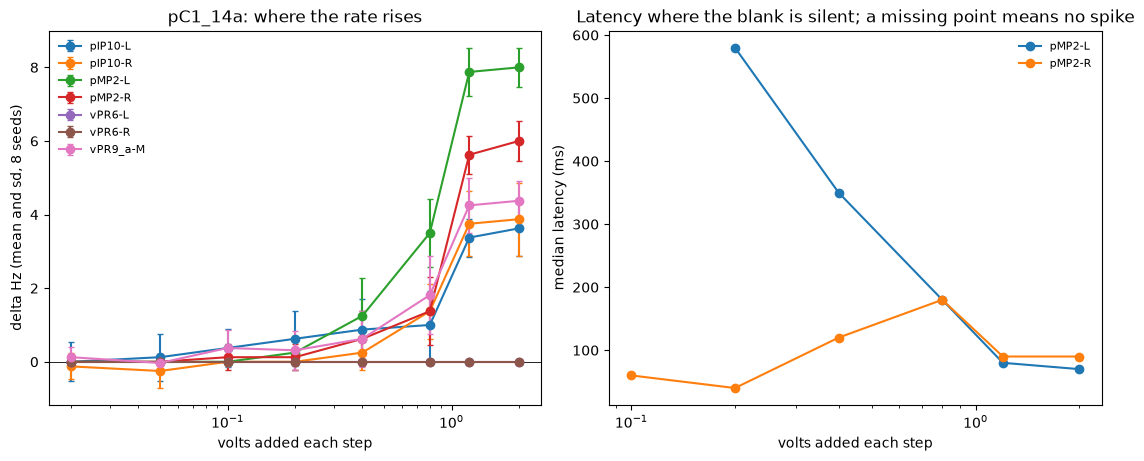

In [5]:
# Strength curve for the strongest type, the near-zero type, and the random group.
# The type survey above is one strength. This grid is extended downward, by halving,
# while that strongest type still raises a pIP10 or pMP2 readout, stopping at 0.001 V/step.
# The same blank and the same 8 seeds are reused. delta is stim minus blank.

DESCEND = [k for k in ("pIP10-L", "pIP10-R", "pMP2-L", "pMP2-R") if k in readouts]
TRACK = DESCEND + [k for k in ("vPR6-L", "vPR6-R", "vPR9_a-M") if k in readouts]

def rises(st):
    return any(st[k]["moves"] and st[k]["delta"] > 0 for k in DESCEND)

def run_one(label, idx, strength):
    t0 = time.perf_counter()
    runs = [trial(idx, seed, strength) for seed in SEEDS]
    st = stats(stack_rates([r[0] for r in runs]))
    lat = stack_latency([r[1] for r in runs])
    print(f"curve {label} strength {strength:.4f} in {time.perf_counter() - t0:.1f}s", flush=True)
    return st, lat

idxs = {strong: neurons(strong), weak: neurons(weak), "random": random_idx}
curve = {strong: {}, weak: {}, "random": {}}
for strength in CURVE_GRID:
    for label in (strong, weak, "random"):
        curve[label][float(strength)] = run_one(label, idxs[label], float(strength))

floor = min(curve[strong])
while floor > 0.001 + 1e-12 and rises(curve[strong][floor][0]):
    floor = floor / 2
    for label in (strong, weak, "random"):
        curve[label][floor] = run_one(label, idxs[label], floor)

strengths = sorted(curve[strong])
print("\nSTRENGTH CURVE. delta Hz is the mean over seeds of stim minus blank. sd is the sample sd of that difference, 8 seeds.")
print(f"{'who':16s} {'V/step':8s} {'readout':12s} {'delta':8s} {'sd':6s} {'t':7s} {'k/n':5s} {'lat':9s} moves")
anchors = {min(strengths), 0.8, max(strengths)}
for label in (strong, weak, "random"):
    for strength in strengths:
        st, lat = curve[label][strength]
        for key in TRACK:
            if label != strong and not st[key]["moves"] and strength not in anchors:
                continue
            print(
                f"{str(label):16s} {strength:8.4f} {key:12s} {st[key]['delta']:+8.2f} {st[key]['sd']:6.2f} "
                f"{st[key]['t']:+7.1f} {lat[key]['k']}/{lat[key]['n']} {lat_ms(lat[key], key):>11s} {st[key]['moves']}"
            )

def wilson(k, n, z=1.96):
    p = k / n
    den = 1 + z * z / n
    center = (p + z * z / (2 * n)) / den
    half = z * ((p * (1 - p) / n + z * z / (4 * n * n)) ** 0.5) / den
    return center - half, center + half

print("\nCANONICAL SUMMARY")
print(LATENCY_DEF)
print(f"Survey strength is {STRENGTH:.1f} V added on each step. Seeds are {list(SEEDS)}. A readout moves when |mean delta| >= {MOVE_HZ:.1f} Hz and |t| >= {MOVE_T:.1f}, with t = mean / (sd / sqrt(n)) and n = {len(SEEDS)}.")
print(f"random_delta is seed 0. random_max_abs is the largest |delta| among the {N_RANDOM} random groups. specific means |delta| exceeds random_max_abs by more than 1 Hz.")
print(f"Wiring onto both pIP10 cells: strongest {strong} signed share {pip_share[strong]:+.4f} (n={len(neurons(strong))}); smallest {weak} signed share {pip_share[weak]:+.4f} (n={len(neurons(weak))}).")
print("Survey rows below use the same fields as the comparison table. fires counts seeds with a spike in the window, including spikes the blank also has.")
for typ in ranked:
    for key in readouts:
        if not interesting(typ, key):
            continue
        share, st, rnd, verdict, flag = verdict_of(typ, key)
        lat = latencies[typ][key]
        lo, hi = wilson(lat["k"], lat["n"])
        print(
            f"survey {typ} {key} share {share:+.4f} delta {st['delta']:+.2f} Hz sd {st['sd']:.2f} "
            f"t {st['t']:+.1f} blank {st['blank']:.2f} Hz random_delta {rnd:+.2f} Hz random_max_abs {control_abs(key):.2f} Hz "
            f"fires {lat['k']}/{lat['n']} wilson95 {lo:.2f} {hi:.2f} latency {lat_ms(lat, key)} "
            f"verdict {verdict} {flag}"
        )

print("Rise check. lowest_move is the smallest strength at which the readout moves and the mean delta is positive. highest_quiet is the largest strength at which that does not happen.")
for key in TRACK:
    ordered = sorted(curve[strong])
    moving = [s for s in ordered if curve[strong][s][0][key]["moves"] and curve[strong][s][0][key]["delta"] > 0]
    quiet = [s for s in ordered if s not in moving]
    lowest_move = "none" if not moving else f"{moving[0]:.4f}"
    highest_quiet = "none" if not quiet else f"{quiet[-1]:.4f}"
    span = [curve[strong][s][0][key]["delta"] for s in ordered]
    print(
        f"curve {strong} {key} lowest_move {lowest_move} highest_quiet {highest_quiet} "
        f"delta_at_min {span[0]:+.2f} delta_at_max {span[-1]:+.2f} delta_range {max(span) - min(span):.2f}"
    )

for label in (weak, "random"):
    n_hit = sum(1 for s in curve[label] for k in DESCEND if curve[label][s][0][k]["moves"])
    print(f"curve {label} descending readout moves at {n_hit} strength x readout pairs")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
xs = sorted(curve[strong])
for key in TRACK:
    ys = [curve[strong][s][0][key]["delta"] for s in xs]
    ss = [curve[strong][s][0][key]["sd"] for s in xs]
    axes[0].errorbar(xs, ys, yerr=ss, marker="o", capsize=2, label=key)
axes[0].set_xscale("log")
axes[0].axhline(0, color="black", linewidth=0.6)
axes[0].set_xlabel("volts added each step")
axes[0].set_ylabel("delta Hz (mean and sd, 8 seeds)")
axes[0].set_title(f"{strong}: where the rate rises")
axes[0].legend(frameon=False, fontsize=8)
for key in DESCEND:
    if blank_lat[key]["k"] > 0:
        continue
    ys = [np.nan if curve[strong][s][1][key]["latency_s"] is None else curve[strong][s][1][key]["latency_s"] * 1000 for s in xs]
    axes[1].plot(xs, ys, marker="o", label=key)
axes[1].set_xscale("log")
axes[1].set_xlabel("volts added each step")
axes[1].set_ylabel("median latency (ms)")
axes[1].set_title("Latency where the blank is silent; a missing point means no spike")
axes[1].legend(frameon=False, fontsize=8)
fig.savefig(FIG / "strength-curve.png", dpi=140)
plt.show()


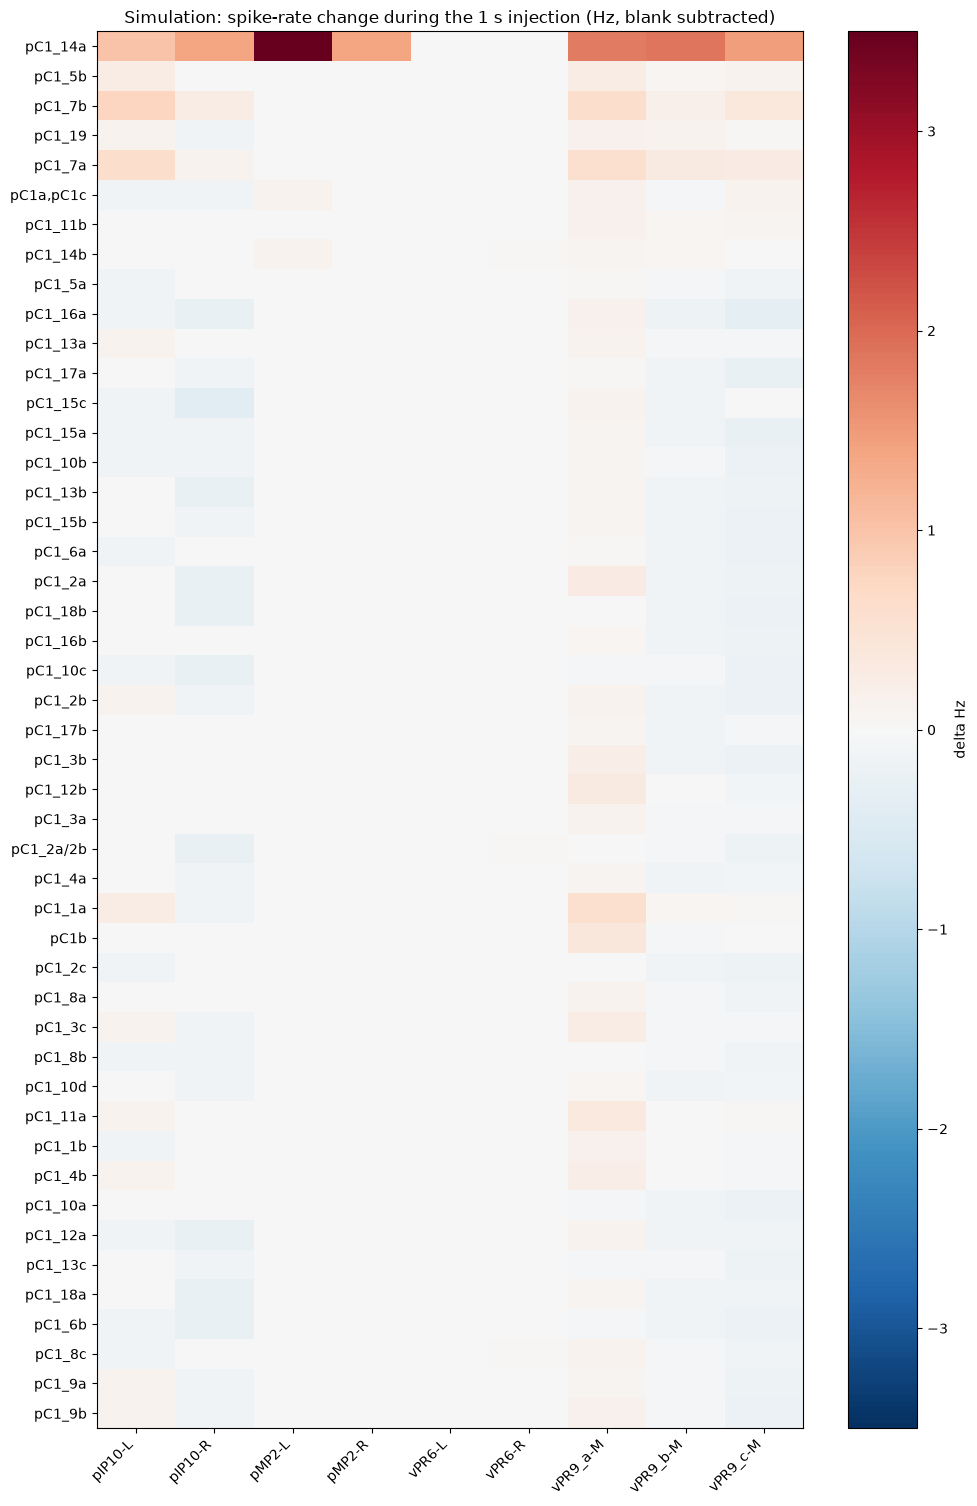

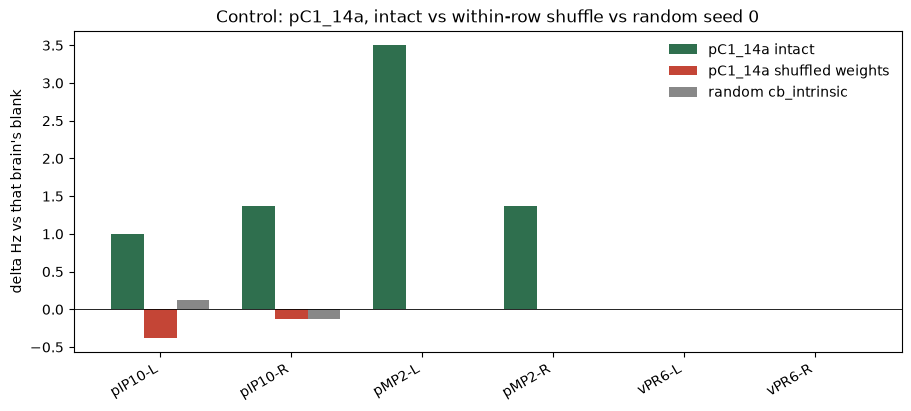

In [6]:

labels = ranked
keys = list(readouts)
mat = np.array([[stim_stats[typ][key]["delta"] for key in keys] for typ in labels])
fig, ax = plt.subplots(figsize=(10, 0.28 * len(labels) + 2))
limit = max(1.0, float(np.max(np.abs(mat))))
im = ax.imshow(mat, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(len(keys)), keys, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.set_title("Simulation: spike-rate change during the 1 s injection (Hz, blank subtracted)")
fig.colorbar(im, ax=ax, label="delta Hz")
fig.tight_layout()
fig.savefig(FIG / "rate-delta.png", dpi=140)
plt.show()

focus = ["pIP10-L", "pIP10-R", "pMP2-L", "pMP2-R", "vPR6-L", "vPR6-R"]
focus = [k for k in focus if k in readouts]
x = np.arange(len(focus))
width = 0.25
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
intact = [stim_stats[strong][k]["delta"] for k in focus]
shuff = [shuffled_stats[strong][k]["delta"] for k in focus]
rand = [stim_stats["random"][k]["delta"] for k in focus]
ax.bar(x - width, intact, width, label=f"{strong} intact", color="#2f6f4e")
ax.bar(x, shuff, width, label=f"{strong} shuffled weights", color="#c44536")
ax.bar(x + width, rand, width, label="random cb_intrinsic", color="#888888")
ax.axhline(0, color="black", linewidth=0.6)
ax.set_xticks(x, focus, rotation=30, ha="right")
ax.set_ylabel("delta Hz vs that brain's blank")
ax.set_title(f"Control: {strong}, intact vs within-row shuffle vs random seed 0")
ax.legend(frameon=False)
fig.savefig(FIG / "shuffle-control.png", dpi=140)
plt.show()


## How to read this, and what the papers say

**Wiring** above is the connectome. **Simulation** is the leaky integrate-and-fire model with the repository's default tonic and gain. A blank at the same noise seed is subtracted. "Moves" means the mean change is at least 1 Hz and the t-score (`mean / standard error`, 8 seeds) is at least 3, the bar in `inject.py`. A direct prediction exists only when that cell type supplies at least 1% of the readout's signed synaptic input. A negative prediction is **floor** when the blank rate is under 0.5 Hz, because this model cannot go below silence. A two-step prediction is one of the five largest absolute path products onto that readout, and only when the direct share is under 1%.

The random control is five draws, seeds 0 through 4, of `cb_intrinsic` neurons that are not `pC1`, each with the same count as the `pC1` type that has the largest absolute direct share onto `pIP10`. The draws are not redone per type. Seed 0 is the group on the strength curve. A readout is specific when its |delta| exceeds the largest |delta| among those five by more than 1 Hz. The other `pC1` types are the per-type control, because every type is stimulated. The shuffled-weights control permutes synapse weights inside each postsynaptic neuron with seed 1. Each cell keeps its incoming weight multiset, so the absolute-input sum stays 1, and the edges do not change. A blank is run on that shuffled brain and subtracted. The weights are restored before the notebook ends.

Papers, as hypotheses:

- von Philipsborn et al. (2011), *Neuron* 69, 509–522. Activation of the descending neuron pIP10 elicits courtship song. This notebook cannot hear song. It can say whether a `pC1` type raises pIP10's spike rate.
- Shiozaki, Wang, Lillvis, Xu, Dickson and Stern (2024), *Nature Neuroscience* 27, 1954–1965, doi:10.1038/s41593-024-01738-9. pIP10 and pMP2 are the two descending pathways they recorded during song. pIP10 is active in pulse and sine song; pMP2 is pulse-selective. vPR9 is a ventral-nerve-cord neuron, recorded in the nerve cord, not a descending neuron. The superclass lines in the first code cell are the file's own labels for those names.
- Ahmed et al. (2023), bioRxiv, doi:10.1101/2023.11.07.566045, title "Transcriptional profiling of Drosophila male-specific P1 (pC1) neurons". That paper uses P1 and pC1 as one name for a cluster. It does not assign MaleCNS strings. The annotation cell prints the MaleCNS v1.0 `synonyms` column (the same feather `flybrain/build.py` downloads; also listed at male-cns.janelia.org). Those synonyms are literature names for the whole `pC1` group, not a map from one `pC1_*` string onto the older name P1. This notebook does not guess that map.
- The connectome is Berg et al. (2026), *Cell*, the MaleCNS release cited as reference 1 in the README.

What would count as reproducing the known circuit: a `pC1` type with a direct excitatory share onto pIP10 that raises pIP10 in the model, by more than 1 Hz beyond every random group, and that loses that move when the incoming weights are permuted inside each postsynaptic cell and the shuffled blank is subtracted. What would count as failing it: no `pC1` type moves pIP10, or the move is within 1 Hz of a random group, or the move survives that permutation. The shuffle-rule lines in the simulation cell are that test, applied as written. vPR neurons are in this simulation only as `vnc_intrinsic` cells. A rate change there is a connectome path into the nerve cord, not evidence that the cell is a descending command, and not evidence of pulse versus sine song. There is no body, so nothing here is courtship behavior.

## Where the numbers are

The code cell that starts with `CANONICAL SUMMARY` is the only statement of the measured numbers. It uses one latency definition, one move rule, and the seed counts `k/n` with a Wilson 95% interval. This markdown does not repeat those numbers. The strength curve is there so the survey strength is not the only point: the grid is extended downward until a pIP10 or pMP2 readout of the strongest type stops rising, or until 0.001 V/step. Plots are written next to the notebook as `direct-pip10.png`, `rate-delta.png`, `shuffle-control.png` and `strength-curve.png`.

Limits. Weights are normalized shares, not raw synapse counts. The step is 20 ms, so a reported latency cannot be finer than that and the rate ceiling is 50 Hz. Photoreceptors are undriven. Tonic, gain and noise are the hand-set defaults, not fitted parameters. Eight seeds. Five random draws. One within-row weight permutation.

Rerun from a fresh install, after `flybrain download` (the first `FlyBrain()` does that, about 260 MB, sha256-checked). The annotation check also fetches the 13 MB body-annotation feather into `~/fly-data/raw/` if it is not already there. Figures are written next to `courtship.ipynb`, found by walking up from the working directory, so the shell does not have to be started in `notebooks/` or the repo root.

```sh
pip install flybrain matplotlib jupyter nbclient ipykernel pyarrow
jupyter nbconvert --to notebook --execute --inplace notebooks/courtship.ipynb
```
